In [1]:

print("VELOOP REWARDS DATA ANALYSIS")
print("Project: Product Telemetry, Data Readiness Audit")
print("Tools: Python, Pandas, Excel and Power BI")
print("Dataset status: SIMULATED DATA")
print("Notebook setup successful!")


VELOOP REWARDS DATA ANALYSIS
Project: Product Telemetry, Data Readiness Audit
Tools: Python, Pandas, Excel and Power BI
Dataset status: SIMULATED DATA
Notebook setup successful!


In [2]:
# Install and import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import os

files = os.listdir("/content")

print("Uploaded files:")
for file in files:
    if file.endswith(".xlsx"):
        print(file)

Uploaded files:
VELOOP_Simulated_User_Behavior_1000.xlsx
VELoop_Rewards_Data_01 (1).xlsx


In [4]:
behavior_file = "/content/VELOOP_Simulated_User_Behavior_1000.xlsx"
rewards_file = "/content/VELoop_Rewards_Data_01 (1).xlsx"

behavior_excel = pd.ExcelFile(behavior_file)
rewards_excel = pd.ExcelFile(rewards_file)

print("BEHAVIOUR WORKBOOK SHEETS:")
print(behavior_excel.sheet_names)

print("\nREWARDS WORKBOOK SHEETS:")
print(rewards_excel.sheet_names)

BEHAVIOUR WORKBOOK SHEETS:
['01_Users_1000', '02_Sessions', '03_Feature_Events', '04_Daily_Activity', '05_Task_Activity', '06_Milestones', '07_Feature_Usage', '08_Data_Dictionary', '09_README_Status', '10_Event_Data_Quality_Audit']

REWARDS WORKBOOK SHEETS:
['Users_1000_Clean', 'Users_Messy_Audit', 'Data_Dictionary', 'Synthetic_Summary', 'README_Data_Status']


In [5]:
behavior_data = {
    sheet: pd.read_excel(behavior_file, sheet_name=sheet)
    for sheet in behavior_excel.sheet_names
}

rewards_data = {
    sheet: pd.read_excel(rewards_file, sheet_name=sheet)
    for sheet in rewards_excel.sheet_names
}

print("All sheets loaded successfully!")

for sheet, df in behavior_data.items():
    print("\nSHEET:", sheet)
    print("Rows and columns:", df.shape)
    print(df.head(3))

All sheets loaded successfully!

SHEET: 01_Users_1000
Rows and columns: (1000, 16)
       user_id     full_name                    email  age             gender  \
0  VLUSR000001  Aditya Patel  aditya.patel1@proton.me   39  Prefer not to say   
1  VLUSR000002  Ananya Sinha  ananya.sinha2@proton.me   37               Male   
2  VLUSR000003  Sakshi Verma  sakshi.verma3@proton.me   24               Male   

       state        city registration_datetime acquisition_source  \
0  Jharkhand  Jamshedpur   2026-07-17 15:13:01           WhatsApp   
1      Assam    Guwahati   2026-08-22 11:21:00           Referral   
2  Jharkhand     Dhanbad   2026-04-15 08:09:48           Referral   

  referral_source_detail primary_device platform account_status  \
0                    NaN        Android      Web      Suspended   
1          Friend/Family        Android      Web       Inactive   
2          Friend/Family        Android      Web       Inactive   

  verification_status onboarding_status referr

In [6]:
audit_results = []

for sheet, df in behavior_data.items():

    audit_results.append({
        "Sheet": sheet,
        "Total Rows": len(df),
        "Total Columns": len(df.columns),
        "Duplicate Rows": df.duplicated().sum(),
        "Missing Values": df.isnull().sum().sum()
    })

audit_df = pd.DataFrame(audit_results)

print(audit_df)

                         Sheet  Total Rows  Total Columns  Duplicate Rows  \
0                01_Users_1000        1000             16               0   
1                  02_Sessions        7913             12               0   
2            03_Feature_Events       35704             13               0   
3            04_Daily_Activity        6667             17               0   
4             05_Task_Activity        9846             12               0   
5                06_Milestones        4799              6               0   
6             07_Feature_Usage          15              7               0   
7           08_Data_Dictionary          26              7               0   
8             09_README_Status          15              2               0   
9  10_Event_Data_Quality_Audit       35714             13              10   

   Missing Values  
0             846  
1             466  
2               0  
3               0  
4           10494  
5              40  
6           

In [7]:
for sheet, df in behavior_data.items():

    missing = df.isnull().sum()

    missing = missing[missing > 0]

    if not missing.empty:
        print("\n", sheet)
        print(missing)


 01_Users_1000
referral_source_detail    846
dtype: int64

 02_Sessions
exit_feature    466
dtype: int64

 05_Task_Activity
task_completed_at    4219
failure_reason       6275
dtype: int64

 06_Milestones
session_id    40
dtype: int64


In [8]:
cleaned_data = {}

for sheet, df in behavior_data.items():

    cleaned_df = df.copy()

    # Remove completely duplicated rows
    cleaned_df = cleaned_df.drop_duplicates()

    # Remove extra spaces from text columns
    for col in cleaned_df.select_dtypes(include="object").columns:
        cleaned_df[col] = cleaned_df[col].str.strip()

    cleaned_data[sheet] = cleaned_df

print("Basic cleaning completed!")

Basic cleaning completed!


In [9]:
# Standardise event status values
if "03_Feature_Events" in cleaned_data:

    df = cleaned_data["03_Feature_Events"]

    if "event_status" in df.columns:
        df["event_status"] = (
            df["event_status"]
            .str.strip()
            .str.lower()
        )

# Standardise gender if available
if "01_Users_1000" in cleaned_data:

    df = cleaned_data["01_Users_1000"]

    if "gender" in df.columns:
        df["gender"] = (
            df["gender"]
            .str.strip()
            .str.title()
        )

print("Category standardisation completed!")

Category standardisation completed!


In [10]:
users = cleaned_data["01_Users_1000"]

print("TOTAL USERS:", len(users))

if "country" in users.columns:
    print("\nUSERS BY COUNTRY:")
    print(users["country"].value_counts())

if "gender" in users.columns:
    print("\nUSERS BY GENDER:")
    print(users["gender"].value_counts())

if "onboarding_status" in users.columns:
    print("\nONBOARDING STATUS:")
    print(users["onboarding_status"].value_counts())

TOTAL USERS: 1000

USERS BY GENDER:
gender
Male                 343
Female               336
Prefer Not To Say    321
Name: count, dtype: int64

ONBOARDING STATUS:
onboarding_status
Completed      685
Started        162
Not Started    153
Name: count, dtype: int64


In [11]:
tasks = cleaned_data["05_Task_Activity"]

print("TASK STATUS COUNTS:")

if "task_status" in tasks.columns:

    print(tasks["task_status"].value_counts())

    completed = (
        tasks["task_status"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("completed")
        .sum()
    )

    total_tasks = len(tasks)

    completion_rate = (
        completed / total_tasks * 100
        if total_tasks > 0 else 0
    )

    print("\nCompleted tasks:", completed)
    print("Total task activity records:", total_tasks)
    print("Task completion rate:", round(completion_rate, 2), "%")

TASK STATUS COUNTS:
task_status
Completed    5627
Abandoned    2051
Failed       1520
Pending       648
Name: count, dtype: int64

Completed tasks: 5627
Total task activity records: 9846
Task completion rate: 57.15 %


In [12]:
sessions = cleaned_data["02_Sessions"]

print("TOTAL SESSIONS:", len(sessions))

if "session_id" in sessions.columns:
    print(
        "Unique sessions:",
        sessions["session_id"].nunique()
    )

if "user_id" in sessions.columns:
    print(
        "Unique active users:",
        sessions["user_id"].nunique()
    )

if "session_start" in sessions.columns:
    print("\nSession start column found.")

TOTAL SESSIONS: 7913
Unique sessions: 7913
Unique active users: 984

Session start column found.


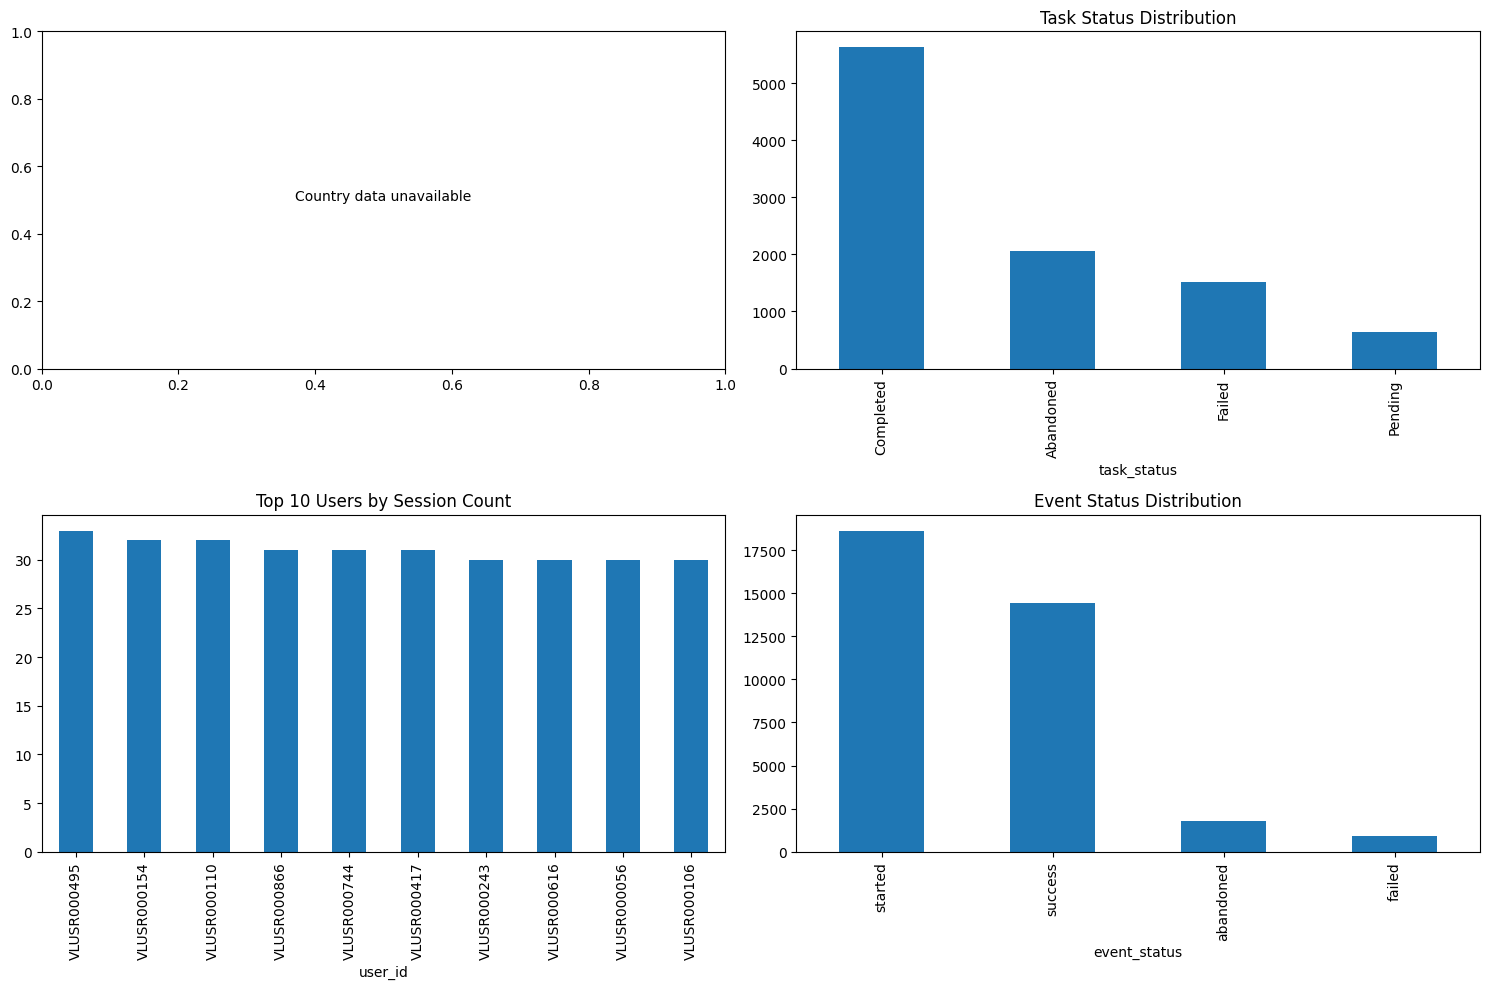

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Chart 1: User country distribution
if "country" in users.columns:
    users["country"].value_counts().head(10).plot(
        kind="bar", ax=axes[0, 0]
    )
    axes[0, 0].set_title("Top User Countries")
    axes[0, 0].set_xlabel("Country")
    axes[0, 0].set_ylabel("Users")
else:
    axes[0, 0].text(0.5, 0.5, "Country data unavailable",
                    ha="center")

# Chart 2: Task status
if "task_status" in tasks.columns:
    tasks["task_status"].value_counts().plot(
        kind="bar", ax=axes[0, 1]
    )
    axes[0, 1].set_title("Task Status Distribution")
else:
    axes[0, 1].text(0.5, 0.5, "Task status unavailable",
                    ha="center")

# Chart 3: Session count by user
if "user_id" in sessions.columns:
    sessions["user_id"].value_counts().head(10).plot(
        kind="bar", ax=axes[1, 0]
    )
    axes[1, 0].set_title("Top 10 Users by Session Count")
else:
    axes[1, 0].text(0.5, 0.5, "Session user data unavailable",
                    ha="center")

# Chart 4: Event status
events = cleaned_data["03_Feature_Events"]

if "event_status" in events.columns:
    events["event_status"].value_counts().plot(
        kind="bar", ax=axes[1, 1]
    )
    axes[1, 1].set_title("Event Status Distribution")
else:
    axes[1, 1].text(0.5, 0.5, "Event status unavailable",
                    ha="center")

plt.tight_layout()
plt.show()

In [14]:
output_file = "/content/VELOOP_Cleaned_Analytics_Workbook.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    for sheet, df in cleaned_data.items():
        safe_sheet_name = sheet[:31]
        df.to_excel(
            writer,
            sheet_name=safe_sheet_name,
            index=False
        )

    audit_df.to_excel(
        writer,
        sheet_name="Data_Quality_Audit",
        index=False
    )

print("Cleaned workbook exported successfully!")

Cleaned workbook exported successfully!


In [15]:
from google.colab import files

files.download(
    "/content/VELOOP_Cleaned_Analytics_Workbook.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
findings = f"""
VELOOP REWARDS – DATA ANALYTICS FINDINGS

PROJECT:
Product Telemetry, Data Readiness Audit and Data Cleaning

TOOLS:
Python, Pandas, NumPy, Matplotlib and Excel

DATASET:
Simulated VELOOP Rewards data.
These results do not represent actual company performance.

DATA QUALITY:
Total behaviour workbook sheets: {len(behavior_data)}

USER ANALYSIS:
Total user records: {len(users)}

SESSION ANALYSIS:
Total session records: {len(sessions)}

TASK ANALYSIS:
Total task activity records: {len(tasks)}

TASK COMPLETION RATE:
{round(completion_rate, 2)}%

VISUALISATION:
A four-panel Python summary chart was generated.

OUTPUT:
Cleaned Excel workbook created for further analysis
and potential Power BI dashboard development.

IMPORTANT:
Wallet reconciliation and retention analysis require
appropriate transaction and date fields. They should
only be reported after verifying that the source data
supports those calculations.
"""

print(findings)

with open("/content/VELOOP_Findings_Report.txt", "w") as f:
    f.write(findings)


VELOOP REWARDS – DATA ANALYTICS FINDINGS

PROJECT:
Product Telemetry, Data Readiness Audit and Data Cleaning

TOOLS:
Python, Pandas, NumPy, Matplotlib and Excel

DATASET:
Simulated VELOOP Rewards data.
These results do not represent actual company performance.

DATA QUALITY:
Total behaviour workbook sheets: 10

USER ANALYSIS:
Total user records: 1000

SESSION ANALYSIS:
Total session records: 7913

TASK ANALYSIS:
Total task activity records: 9846

TASK COMPLETION RATE:
57.15%

VISUALISATION:
A four-panel Python summary chart was generated.

OUTPUT:
Cleaned Excel workbook created for further analysis
and potential Power BI dashboard development.

IMPORTANT:
Wallet reconciliation and retention analysis require
appropriate transaction and date fields. They should
only be reported after verifying that the source data
supports those calculations.



In [17]:
files.download("/content/VELOOP_Findings_Report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# Load the required datasets
users = behavior_data["01_Users_1000"].copy()
daily_activity = behavior_data["04_Daily_Activity"].copy()

# Convert date columns into proper datetime format
users["registration_datetime"] = pd.to_datetime(
    users["registration_datetime"], errors="coerce"
)

daily_activity["activity_date"] = pd.to_datetime(
    daily_activity["activity_date"], errors="coerce"
)

# Keep the calendar date only
users["registration_date"] = users["registration_datetime"].dt.normalize()
daily_activity["activity_date"] = daily_activity["activity_date"].dt.normalize()

# Find each user's unique active dates
active_dates = daily_activity[
    ["user_id", "activity_date"]
].dropna().drop_duplicates()

print("Users:", users["user_id"].nunique())
print("Unique user activity dates:", len(active_dates))
print("Latest activity date:", active_dates["activity_date"].max())

Users: 1000
Unique user activity dates: 6667
Latest activity date: 2026-09-15 00:00:00


In [19]:
# Get the last date available in the activity dataset
last_activity_date = active_dates["activity_date"].max()

# Prepare a retention result
retention_results = []

for day in [1, 7, 14]:

    # Only include users who have had enough time to reach this day
    eligible_users = users[
        users["registration_date"].notna() &
        (users["registration_date"] + pd.to_timedelta(day, unit="D")
         <= last_activity_date)
    ]

    # Expected activity date for each eligible user
    expected = eligible_users[
        ["user_id", "registration_date"]
    ].copy()

    expected["expected_activity_date"] = (
        expected["registration_date"] +
        pd.to_timedelta(day, unit="D")
    )

    # Check whether the user was active on that exact date
    matched = expected.merge(
        active_dates,
        left_on=["user_id", "expected_activity_date"],
        right_on=["user_id", "activity_date"],
        how="inner"
    )

    eligible_count = len(eligible_users)
    retained_count = matched["user_id"].nunique()

    retention_rate = (
        retained_count / eligible_count * 100
        if eligible_count else 0
    )

    retention_results.append({
        "Retention Day": f"D{day}",
        "Eligible Users": eligible_count,
        "Retained Users": retained_count,
        "Retention Rate (%)": round(retention_rate, 2)
    })

retention_df = pd.DataFrame(retention_results)

print(retention_df)

  Retention Day  Eligible Users  Retained Users  Retention Rate (%)
0            D1             994             178               17.91
1            D7             953             127               13.33
2           D14             904             109               12.06


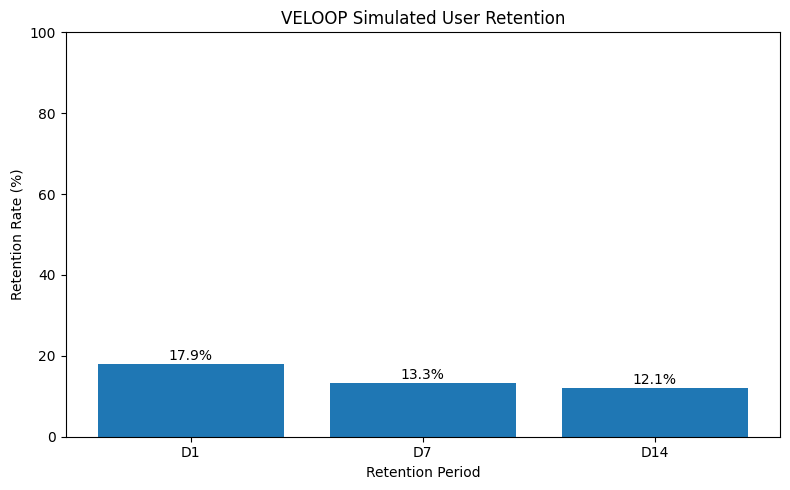

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(
    retention_df["Retention Day"],
    retention_df["Retention Rate (%)"]
)

plt.title("VELOOP Simulated User Retention")
plt.xlabel("Retention Period")
plt.ylabel("Retention Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(retention_df["Retention Rate (%)"]):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

In [21]:
rewards_users = rewards_data["Users_1000_Clean"].copy()

print("REWARDS WORKBOOK USER COLUMNS:")
for column in rewards_users.columns:
    print(column)

REWARDS WORKBOOK USER COLUMNS:
user_id
full_name
email
age
gender
state
city
registration_datetime
acquisition_source
referral_source_detail
primary_device
platform
account_status
email_verification_status
onboarding_status
last_login_datetime
lifetime_sessions
active_days
xp_balance
referral_code
days_since_registration
is_active_7d
is_active_30d
consent_status
marketing_opt_in
account_created_via
country


In [22]:
balance_columns = [
    col for col in rewards_users.columns
    if any(word in col.lower() for word in [
        "wallet", "balance", "earned", "withdraw",
        "transaction", "reward", "xp"
    ])
]

print("Potential wallet and reward fields:")
print(balance_columns)

if balance_columns:
    print(rewards_users[balance_columns].head(10))

Potential wallet and reward fields:
['xp_balance']
   xp_balance
0          76
1         234
2         227
3         136
4         146
5          96
6         172
7         189
8         545
9         213


In [23]:
wallet_audit = pd.DataFrame([
    {
        "Required Data": "Stored wallet balance",
        "Available Field": "wallet_balance",
        "Status": "Not found in inspected workbook columns"
    },
    {
        "Required Data": "Total amount earned",
        "Available Field": "earned_amount",
        "Status": "Not found in inspected workbook columns"
    },
    {
        "Required Data": "Total amount withdrawn",
        "Available Field": "withdrawn_amount",
        "Status": "Not found in inspected workbook columns"
    },
    {
        "Required Data": "Wallet transaction history",
        "Available Field": "transaction_id / transaction_type",
        "Status": "No transaction ledger identified"
    },
    {
        "Required Data": "XP balance",
        "Available Field": "xp_balance",
        "Status": "Available in rewards user table"
    }
])

print(wallet_audit)

                Required Data                    Available Field  \
0       Stored wallet balance                     wallet_balance   
1         Total amount earned                      earned_amount   
2      Total amount withdrawn                   withdrawn_amount   
3  Wallet transaction history  transaction_id / transaction_type   
4                  XP balance                         xp_balance   

                                    Status  
0  Not found in inspected workbook columns  
1  Not found in inspected workbook columns  
2  Not found in inspected workbook columns  
3         No transaction ledger identified  
4          Available in rewards user table  


In [24]:
# Convert XP balance to numeric values
rewards_users["xp_balance"] = pd.to_numeric(
    rewards_users["xp_balance"], errors="coerce"
)

print("XP BALANCE SUMMARY")
print(rewards_users["xp_balance"].describe())

print("\nMissing XP balances:")
print(rewards_users["xp_balance"].isna().sum())

print("\nUsers with zero XP:")
print((rewards_users["xp_balance"] == 0).sum())

XP BALANCE SUMMARY
count    1000.000000
mean      231.889000
std       168.633793
min         5.000000
25%       109.000000
50%       191.500000
75%       305.750000
max      1156.000000
Name: xp_balance, dtype: float64

Missing XP balances:
0

Users with zero XP:
0


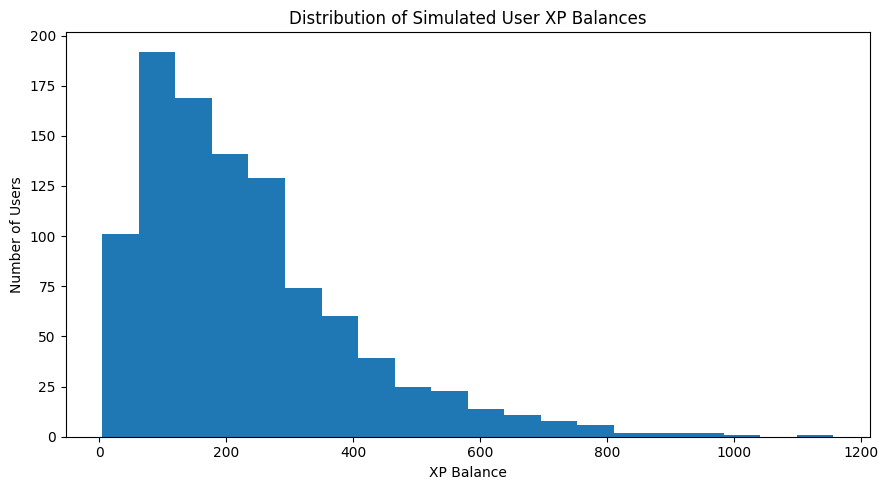

In [25]:
plt.figure(figsize=(9, 5))

rewards_users["xp_balance"].dropna().plot(
    kind="hist", bins=20
)

plt.title("Distribution of Simulated User XP Balances")
plt.xlabel("XP Balance")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

In [26]:
# Create a user-level retention table
retention_users = users[
    ["user_id", "registration_date"]
].copy()

for day in [1, 7, 14]:

    retention_users[f"D{day}_date"] = (
        retention_users["registration_date"] +
        pd.to_timedelta(day, unit="D")
    )

    active_check = active_dates.rename(
        columns={"activity_date": f"D{day}_date"}
    )

    retention_users = retention_users.merge(
        active_check,
        on=["user_id", f"D{day}_date"],
        how="left",
        indicator=f"D{day}_match"
    )

    retention_users[f"D{day}_retained"] = (
        retention_users[f"D{day}_match"] == "both"
    ).astype(int)

    # Users who have not yet reached the retention day
    # are marked as not eligible, rather than non-retained
    eligible = (
        retention_users[f"D{day}_date"] <= last_activity_date
    )

    retention_users.loc[
        ~eligible, f"D{day}_retained"
    ] = np.nan

    retention_users[f"D{day}_eligible"] = eligible.astype(int)

print(retention_users.head())

       user_id registration_date    D1_date   D1_match  D1_retained  \
0  VLUSR000001        2026-07-17 2026-07-18  left_only          0.0   
1  VLUSR000002        2026-08-22 2026-08-23  left_only          0.0   
2  VLUSR000003        2026-04-15 2026-04-16  left_only          0.0   
3  VLUSR000004        2026-07-13 2026-07-14  left_only          0.0   
4  VLUSR000005        2026-09-14 2026-09-15  left_only          0.0   

   D1_eligible    D7_date   D7_match  D7_retained  D7_eligible   D14_date  \
0            1 2026-07-24  left_only          0.0            1 2026-07-31   
1            1 2026-08-29  left_only          0.0            1 2026-09-05   
2            1 2026-04-22  left_only          0.0            1 2026-04-29   
3            1 2026-07-20  left_only          0.0            1 2026-07-27   
4            1 2026-09-21  left_only          NaN            0 2026-09-28   

   D14_match  D14_retained  D14_eligible  
0  left_only           0.0             1  
1  left_only           0

In [27]:
final_output = "/content/VELOOP_Python_Analytics_Results.xlsx"

with pd.ExcelWriter(final_output, engine="openpyxl") as writer:

    audit_df.to_excel(
        writer,
        sheet_name="Data_Quality_Audit",
        index=False
    )

    retention_df.to_excel(
        writer,
        sheet_name="Retention_Summary",
        index=False
    )

    retention_users.to_excel(
        writer,
        sheet_name="User_Retention",
        index=False
    )

    wallet_audit.to_excel(
        writer,
        sheet_name="Wallet_Data_Audit",
        index=False
    )

    rewards_users[
        ["user_id", "xp_balance"]
    ].to_excel(
        writer,
        sheet_name="User_XP_Balance",
        index=False
    )

    users.to_excel(
        writer,
        sheet_name="Users",
        index=False
    )

    daily_activity.to_excel(
        writer,
        sheet_name="Daily_Activity",
        index=False
    )

print("Final Python analytics workbook created!")

Final Python analytics workbook created!


In [28]:
from google.colab import files

files.download(
    "/content/VELOOP_Python_Analytics_Results.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
report = f"""
VELOOP REWARDS
PYTHON DATA ANALYTICS REPORT

PROJECT:
Product Telemetry, Data Readiness Audit and Wallet Data Inspection

DATA SOURCE:
Simulated VELOOP datasets. Results are for analytical practice
and must not be represented as actual company performance.

TOOLS:
Python, Pandas, NumPy, Matplotlib and Excel.

1. DATA QUALITY
{audit_df.to_string(index=False)}

2. USER RETENTION
{retention_df.to_string(index=False)}

Retention definition:
D1, D7 and D14 measure users active exactly 1, 7 or 14
calendar days after their registration date.
Only users who had enough observation time are eligible.

3. XP BALANCE
{rewards_users["xp_balance"].describe().to_string()}

XP balance is analysed separately and is not treated as cash.

4. WALLET RECONCILIATION
A complete wallet transaction ledger was not identified
in the inspected workbook columns. Earned amounts,
withdrawals and stored wallet balances could not be
reconciled from the available fields.

5. OUTPUT
VELOOP_Python_Analytics_Results.xlsx

6. LIMITATIONS
All data is simulated.
Retention depends on the available observation period.
Wallet reconciliation requires a transaction-level
ledger with earned, withdrawn and balance information.
"""

with open("/content/VELOOP_Python_Analytics_Report.txt", "w") as f:
    f.write(report)

print("Written report created!")

Written report created!


In [30]:
files.download(
    "/content/VELOOP_Python_Analytics_Report.txt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>